# Figuras para la Tesis (MIL Multimodal)
Generación de figuras vectorizadas para el documento de tesis: alineación geométrica, atención temporal, espacio geométrico, matriz de confusión del modelo vigente (`objetivo3_evaluacion_v2.json`), curvas de entrenamiento con el gap de sobreajuste, y el modelo al lado de sus líneas de base (`objetivo3_lineas_de_base.json`).

Requiere haber corrido antes `scripts/evaluar_v2.py` y `scripts/evaluar_lineas_de_base.py`.

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


Entorno         : local
Raíz de proyecto: /media/sergio/Expansion/UGR/Licenciatura en Ciencias de datos/cuatrimestre3/materias/seminario trabajo final/Tesina/expresiones_faciales_equinos/datos_equinos
Área de trabajo : /media/sergio/Expansion/UGR/Licenciatura en Ciencias de datos/cuatrimestre3/materias/seminario trabajo final/Tesina/expresiones_faciales_equinos/datos_equinos/trabajo

Generando Figura 1...


/home/sergio/.venvs/tesina-equinos/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


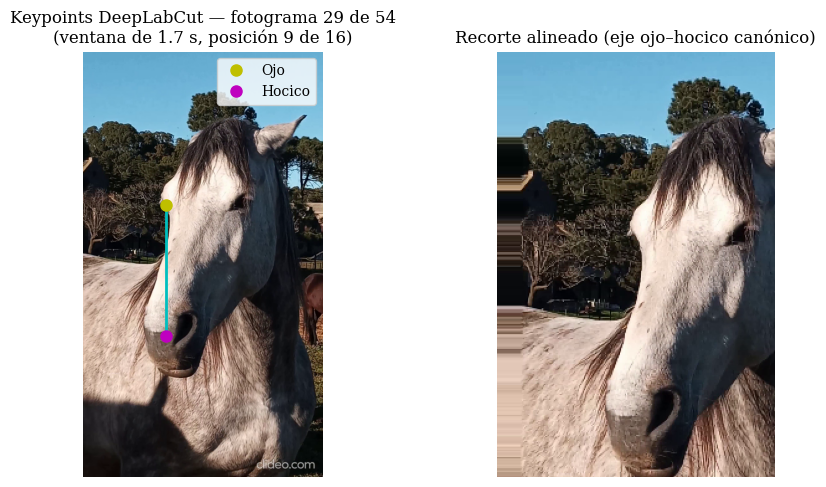


Generando Figura 2...


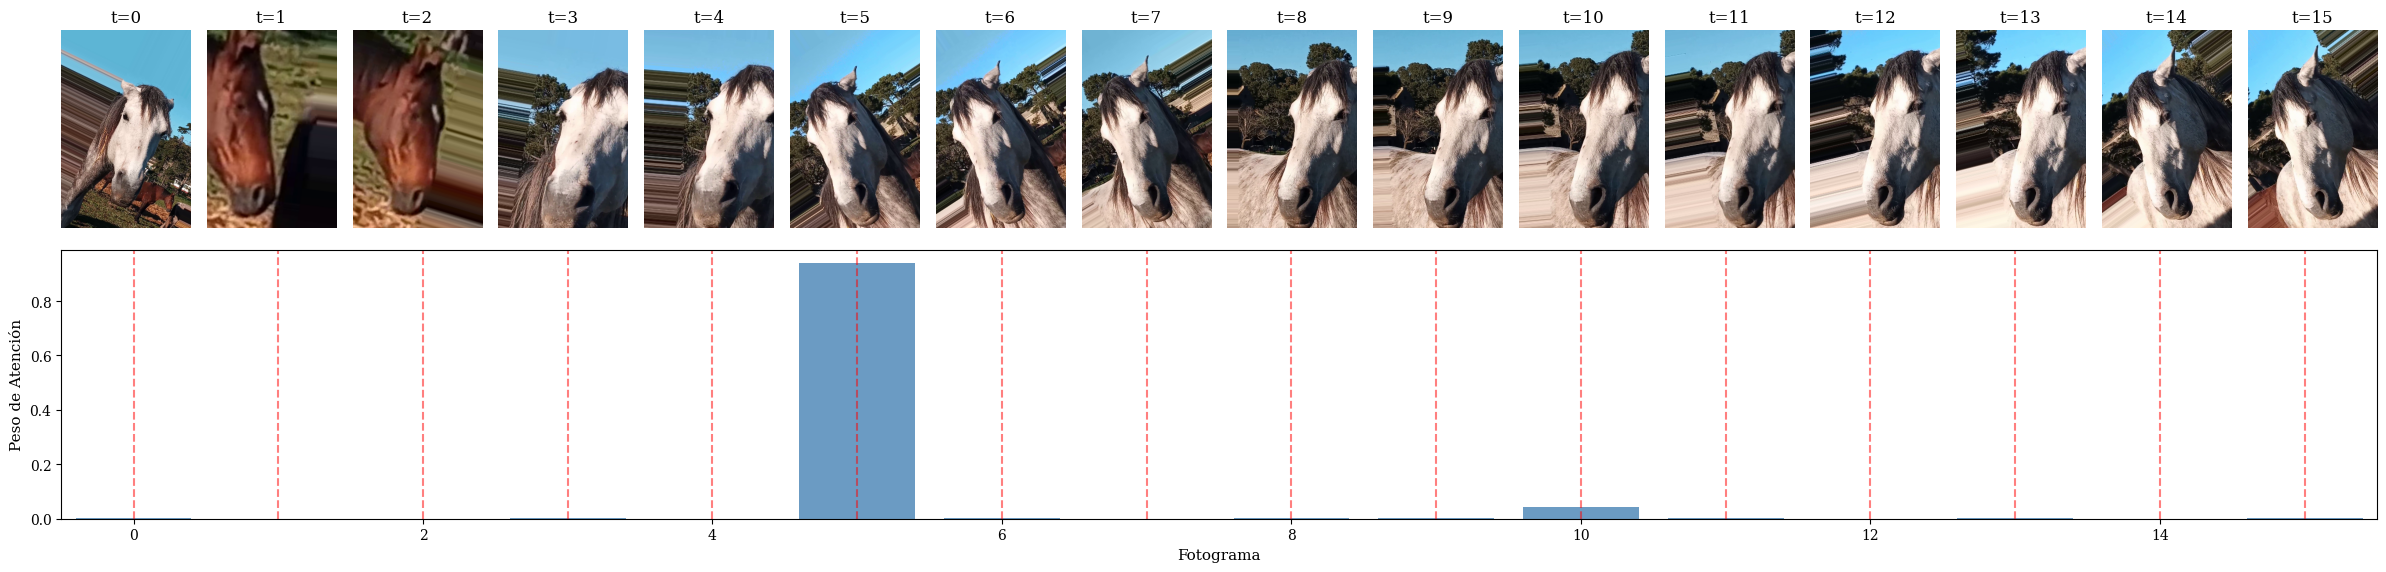


Generando Figura 3...


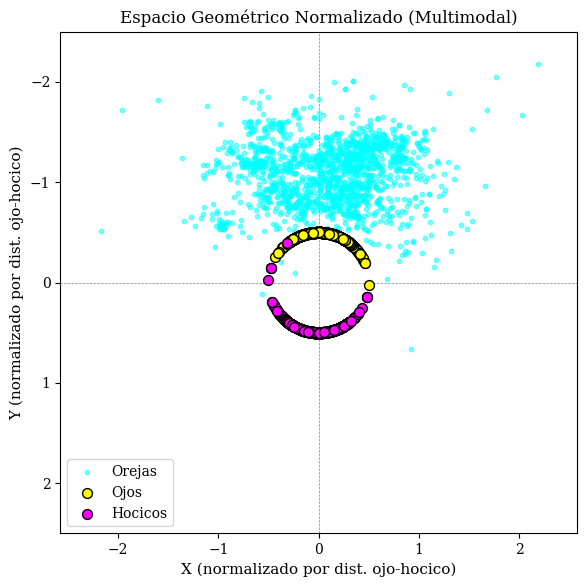


Generando Figura 4...


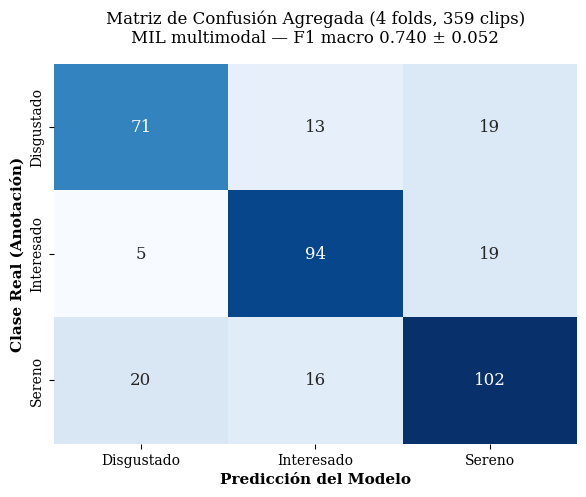


Generando Figura 5...


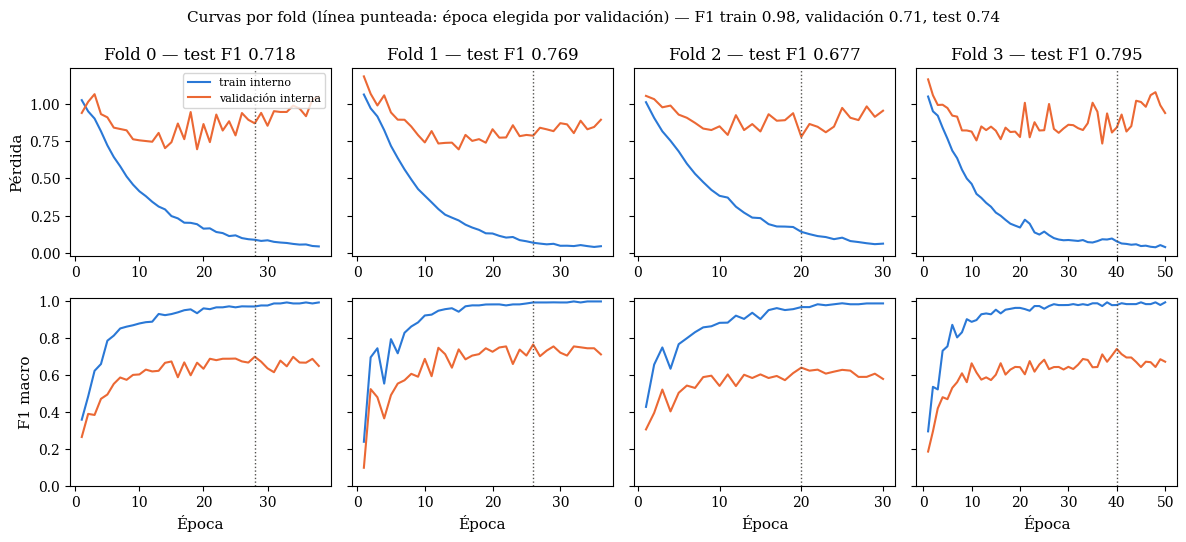


Generando Figura 6...


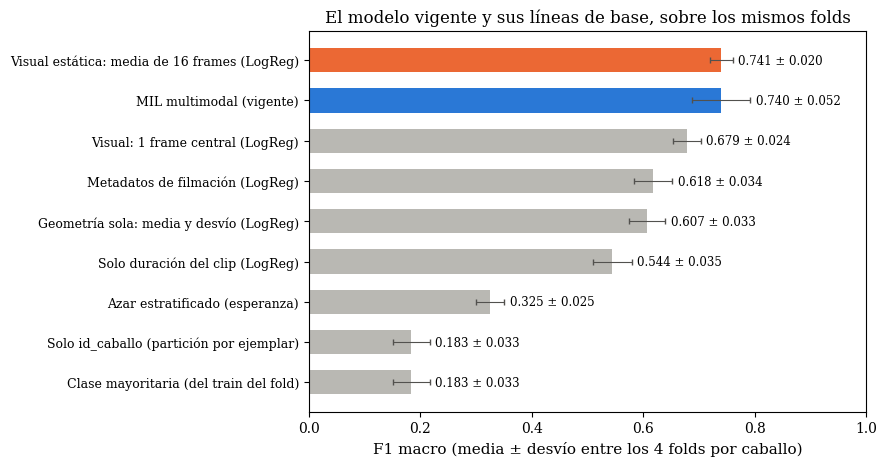


Figuras generadas en /media/sergio/Expansion/UGR/Licenciatura en Ciencias de datos/cuatrimestre3/materias/seminario trabajo final/Tesina/expresiones_faciales_equinos/datos_equinos/resultados/figuras


In [2]:
import sys
import json
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import traceback

# Configuración LaTeX para Matplotlib
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Computer Modern Roman", "DejaVu Serif"],
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14
})

sys.path.append(str(Path.cwd()))
from equinos import rutas, inferencia, clasificacion, caracteristicas

def main():
    rutas.inicializar()
    dir_figuras = rutas.carpeta("resultados") / "figuras"
    dir_figuras.mkdir(parents=True, exist_ok=True)
    
    # -------------------------------------------------------------------------
    # Figura 1: Preprocesamiento y Alineación
    # -------------------------------------------------------------------------
    try:
        print("\nGenerando Figura 1...")
        video_id = "240_20260903-084041_yW6FmTyX"
        import os
        base_videos = Path(os.environ.get("TESINA_EQUINOS_VIDEOS", rutas.carpeta("videos") / "Videos de prueba"))
        ruta_video = base_videos / "Disgustado" / f"{video_id}.mp4"
        
        if not ruta_video.exists():
            print(f"[Error] No se encontró el video {ruta_video}")
        else:
            # La misma cadena que el entrenamiento y la interfaz: pose de DeepLabCut sobre todo el
            # video, ventana y anclaje de `alineado.preparar_secuencia`, y recorte. Se muestra el
            # fotograma que la selección ELIGE para la posición central de la secuencia. (La
            # versión anterior usaba la caja de YOLO, que ya no participa, y mostraba el fotograma
            # 8 del video en lugar del 8.º de la secuencia.)
            from equinos import alineado, pose, secuencia
            parametros = inferencia.parametros_etapa02()
            cap = cv2.VideoCapture(str(ruta_video))
            total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
            filas = inferencia._pose_completa(ruta_video, total, parametros)
            prep = alineado.preparar_secuencia(filas, total=total, fps=fps, p=parametros,
                                               minimo=secuencia.FRAMES_POR_CLIP)
            # Los 16 recortes de la secuencia: la figura 2 los muestra junto a la atención.
            recortes, crudos = [], []
            for o, matriz in zip(prep.ordenes, prep.matrices):
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(o))
                ok, img = cap.read()
                crudos.append(img)
                recortes.append(alineado.recortar(img, matriz, prep.destino))
            cap.release()
            posicion = len(prep.ordenes) // 2
            orden = prep.ordenes[posicion]
            imagen, recorte = crudos[posicion], recortes[posicion]
            pares = pose.seleccionar_par([f for f in filas if int(f["orden"]) == int(orden)])
            pt = pares[0] if pares else None

            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
            ax1.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            if pt and pt["x_ojo"] == pt["x_ojo"] and pt["x_hocico"] == pt["x_hocico"]:
                ax1.plot([pt["x_ojo"], pt["x_hocico"]], [pt["y_ojo"], pt["y_hocico"]], 'c-', linewidth=2)
                ax1.plot(pt["x_ojo"], pt["y_ojo"], 'yo', markersize=8, label="Ojo")
                ax1.plot(pt["x_hocico"], pt["y_hocico"], 'mo', markersize=8, label="Hocico")
                ax1.legend()
            ax1.set_title(f"Keypoints DeepLabCut — fotograma {orden} de {total}\n"
                          f"(ventana de {prep.span_seg:.1f} s, posición {posicion + 1} de 16)")
            ax1.axis("off")

            ax2.imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
            ax2.set_title("Recorte alineado (eje ojo–hocico canónico)")
            ax2.axis("off")

            plt.tight_layout()
            plt.savefig(dir_figuras / "figura1_preprocesamiento.pdf", bbox_inches='tight')
            plt.savefig(dir_figuras / "figura1_preprocesamiento.png", dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    except Exception as e:
        print("[Fallo Figura 1]")
        traceback.print_exc()

    # -------------------------------------------------------------------------
    # Figura 2: Secuencia y Pesos de Atención (MIL)
    # -------------------------------------------------------------------------
    try:
        print("\nGenerando Figura 2...")
        if not ruta_video.exists():
            print(f"[Error] No se encontró el video {ruta_video}")
        else:
            resultado = inferencia.clasificar_video(ruta_video, progreso=lambda *args, **kwargs: None)
            atencion = resultado.atencion
            
            if atencion is not None and len(recortes) > 0:
                n_frames = min(16, len(recortes))
                recortes_clip = recortes[:n_frames]
                atencion_clip = atencion[:n_frames]
                
                idx_mostrar = list(range(len(recortes_clip)))
                
                fig = plt.figure(figsize=(24, 6))
                gs = fig.add_gridspec(2, len(idx_mostrar), height_ratios=[1, 1])
                
                for i, idx in enumerate(idx_mostrar):
                    ax = fig.add_subplot(gs[0, i])
                    ax.imshow(cv2.cvtColor(recortes_clip[idx], cv2.COLOR_BGR2RGB))
                    ax.axis('off')
                    ax.set_title(f"t={idx}")
                    
                ax_att = fig.add_subplot(gs[1, :])
                tiempo = np.arange(len(atencion_clip))
                ax_att.bar(tiempo, atencion_clip, color='steelblue', alpha=0.8)
                ax_att.set_xlabel("Fotograma")
                ax_att.set_ylabel("Peso de Atención")
                ax_att.set_xlim(-0.5, len(atencion_clip)-0.5)
                for i, idx in enumerate(idx_mostrar):
                    ax_att.axvline(x=idx, color='red', linestyle='--', alpha=0.5)
                    
                plt.tight_layout()
                plt.savefig(dir_figuras / "figura2_atencion.pdf", bbox_inches='tight')
                plt.savefig(dir_figuras / "figura2_atencion.png", dpi=300, bbox_inches='tight')
                plt.show()
                plt.close()
    except Exception as e:
        print("[Fallo Figura 2]")
        traceback.print_exc()

    # -------------------------------------------------------------------------
    # Figura 3: Espacio Geométrico Normalizado
    # -------------------------------------------------------------------------
    try:
        print("\nGenerando Figura 3...")
        # La evaluación y la pose VIGENTES. Antes se leían `objetivo3_evaluacion.json` (el modelo
        # de promedio sobre 153 clips) y `pose_completa.csv` (la pose de la corrida v1), y las
        # figuras 3 y 4 describían otro modelo que el que sirve la interfaz.
        eval_path = rutas.carpeta("resultados") / clasificacion.ARCHIVO_EVALUACION
        if eval_path.exists():
            from equinos import pose
            from equinos import dataset as _ds
            pose_filas = pose.leer_pose(rutas.carpeta("resultados") / _ds.ARCHIVO_POSE_SELECCIONADA)
            
            fig, ax = plt.subplots(figsize=(6, 6))
            ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
            ax.axvline(0, color='gray', linestyle='--', linewidth=0.5)
            
            import random
            from collections import defaultdict
            pose_por_clip = defaultdict(lambda: defaultdict(list))
            for f in pose_filas:
                pose_por_clip[f['clip']][int(f['orden'])].append(f)
                
            def mejor_de(candidatos, frames_medidos):
                mejor = (float("nan"), float("nan"), -1.0)
                for c in candidatos:
                    for f in frames_medidos:
                        if f['bodypart'].lower() == c.lower() or c.lower() in f['bodypart'].lower():
                            conf = float(f['confianza'])
                            if conf > mejor[2]:
                                mejor = (float(f['x']), float(f['y']), conf)
                return mejor
    
            import math
            puntos_ojo = []
            puntos_hoc = []
            puntos_ore = []
            
            clips_lista = list(pose_por_clip.keys())
            random.seed(42)
            clips_muestra = random.sample(clips_lista, min(100, len(clips_lista)))
            
            for clip in clips_muestra:
                frames_del_clip = pose_por_clip[clip]
                for orden in range(len(frames_del_clip)):
                    medidos = frames_del_clip[orden]
                    x_ojo, y_ojo, c_ojo = mejor_de(["eye"], medidos)
                    x_hoc, y_hoc, c_hoc = mejor_de(["nose", "snout", "muzzle", "upper_jaw", "mouth"], medidos)
                    x_ore, y_ore, c_ore = mejor_de(["earbase", "earend"], medidos)
                    
                    if c_ojo > 0 and c_hoc > 0:
                        cx, cy = (x_ojo + x_hoc) / 2, (y_ojo + y_hoc) / 2
                        escala = math.hypot(x_ojo - x_hoc, y_ojo - y_hoc)
                        if escala < 1e-6: escala = 1.0
                        
                        def normalizar(x, y, c):
                            if c > 0.0 and not math.isnan(x) and not math.isnan(y):
                                return (x - cx) / escala, (y - cy) / escala
                            return None, None
                            
                        nx_ojo, ny_ojo = normalizar(x_ojo, y_ojo, c_ojo)
                        nx_hoc, ny_hoc = normalizar(x_hoc, y_hoc, c_hoc)
                        nx_ore, ny_ore = normalizar(x_ore, y_ore, c_ore)
                        
                        if nx_ojo is not None: puntos_ojo.append((nx_ojo, ny_ojo))
                        if nx_hoc is not None: puntos_hoc.append((nx_hoc, ny_hoc))
                        if nx_ore is not None: puntos_ore.append((nx_ore, ny_ore))
            
            if puntos_ore:
                ox, oy = zip(*puntos_ore)
                ax.scatter(ox, oy, alpha=0.5, color='cyan', label='Orejas', s=10, zorder=2)
            if puntos_ojo:
                ojx, ojy = zip(*puntos_ojo)
                ax.scatter(ojx, ojy, color='yellow', edgecolor='black', s=50, label='Ojos', zorder=5)
            if puntos_hoc:
                hx, hy = zip(*puntos_hoc)
                ax.scatter(hx, hy, color='magenta', edgecolor='black', s=50, label='Hocicos', zorder=5)
            
            ax.invert_yaxis()
            ax.set_xlim(-2.5, 2.5)
            ax.set_ylim(2.5, -2.5) 
            
            ax.set_aspect('equal', adjustable='datalim')
            ax.set_title("Espacio Geométrico Normalizado (Multimodal)")
            ax.set_xlabel("X (normalizado por dist. ojo-hocico)")
            ax.set_ylabel("Y (normalizado por dist. ojo-hocico)")
            ax.legend()
            
            plt.tight_layout()
            plt.savefig(dir_figuras / "figura3_espacio_geometrico.pdf", bbox_inches='tight')
            plt.savefig(dir_figuras / "figura3_espacio_geometrico.png", dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    except Exception as e:
        print("[Fallo Figura 3]")
        traceback.print_exc()

    # -------------------------------------------------------------------------
    # Figura 4: Matriz de Confusión Final
    # -------------------------------------------------------------------------
    try:
        print("\nGenerando Figura 4...")
        if eval_path.exists():
            datos = json.loads(eval_path.read_text(encoding='utf-8'))
            preds = datos["predicciones_fuera_de_muestra"]
            
            clases = clasificacion.CLASES
            matriz = np.zeros((len(clases), len(clases)), dtype=int)
            mapa_idx = {c: i for i, c in enumerate(clases)}
            
            for p in preds:
                r = mapa_idx[p["real"]]
                pr = mapa_idx[p["predicha"]]
                matriz[r, pr] += 1
                
            fig, ax = plt.subplots(figsize=(6, 5))
            sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', 
                        xticklabels=clases, yticklabels=clases, ax=ax,
                        cbar=False, annot_kws={"size": 12})
            ax.set_xlabel("Predicción del Modelo", fontweight='bold')
            ax.set_ylabel("Clase Real (Anotación)", fontweight='bold')
            n = len(preds)
            f1 = datos["resumen"]["f1_macro"]; desvio = datos["resumen"]["f1_macro_desvio"]
            ax.set_title(f"Matriz de Confusión Agregada (4 folds, {n} clips)\n"
                         f"MIL multimodal — F1 macro {f1:.3f} ± {desvio:.3f}", pad=15)
            
            plt.tight_layout()
            plt.subplots_adjust(top=0.88)
            plt.savefig(dir_figuras / "figura4_matriz_confusion.pdf", bbox_inches='tight', pad_inches=0.2)
            plt.savefig(dir_figuras / "figura4_matriz_confusion.png", dpi=300, bbox_inches='tight', pad_inches=0.2)
            plt.show()
            plt.close()
    except Exception as e:
        print("[Fallo Figura 4]")
        traceback.print_exc()

    # -------------------------------------------------------------------------
    # Figura 5: Curvas de entrenamiento y sobreajuste
    # -------------------------------------------------------------------------
    # Pérdida y F1 del train interno (evaluado sin dropout) y de la validación interna, por fold.
    # El test NO se grafica por época: el pipeline no lo mira hasta el final, y graficarlo
    # invitaría a leer en él la época que convenía.
    try:
        print("\nGenerando Figura 5...")
        datos = json.loads(eval_path.read_text(encoding='utf-8'))
        folds = datos["por_fold"]
        if "f1_train" not in folds[0]["curva"][0]:
            print("[Figura 5] La evaluación no registra el train: re-ejecutar scripts/evaluar_v2.py")
        else:
            fig, axs = plt.subplots(2, len(folds), figsize=(12, 5.5), sharey="row")
            for k, f in enumerate(folds):
                ep = [e["epoca"] for e in f["curva"]]
                axs[0, k].plot(ep, [e["loss_train_eval"] for e in f["curva"]], color="#2a78d6", label="train interno")
                axs[0, k].plot(ep, [e["loss_val"] for e in f["curva"]], color="#eb6834", label="validación interna")
                axs[1, k].plot(ep, [e["f1_train"] for e in f["curva"]], color="#2a78d6", label="train interno")
                axs[1, k].plot(ep, [e["f1_val"] for e in f["curva"]], color="#eb6834", label="validación interna")
                for fila in (0, 1):
                    axs[fila, k].axvline(f["mejor_epoca"], color="#52514e", ls=":", lw=1)
                axs[0, k].set_title(f"Fold {f['fold']} — test F1 {f['f1_macro']:.3f}")
                axs[1, k].set_xlabel("Época")
                axs[1, k].set_ylim(0, 1.02)
            axs[0, 0].set_ylabel("Pérdida")
            axs[1, 0].set_ylabel("F1 macro")
            axs[0, 0].legend(loc="upper right", fontsize=8)
            s = datos["resumen"]["sobreajuste"]
            fig.suptitle(f"Curvas por fold (línea punteada: época elegida por validación) — "
                         f"F1 train {s['f1_train_media']:.2f}, validación {s['f1_validacion_media']:.2f}, "
                         f"test {datos['resumen']['f1_macro']:.2f}", fontsize=11)
            plt.tight_layout()
            plt.savefig(dir_figuras / "figura5_curvas_sobreajuste.pdf", bbox_inches='tight')
            plt.savefig(dir_figuras / "figura5_curvas_sobreajuste.png", dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    except Exception as e:
        print("[Fallo Figura 5]")
        traceback.print_exc()

    # -------------------------------------------------------------------------
    # Figura 6: El modelo al lado de sus líneas de base
    # -------------------------------------------------------------------------
    try:
        print("\nGenerando Figura 6...")
        ruta_lb = rutas.carpeta("resultados") / "objetivo3_lineas_de_base.json"
        if not ruta_lb.exists():
            print("[Figura 6] Falta objetivo3_lineas_de_base.json: correr scripts/evaluar_lineas_de_base.py")
        else:
            lb = json.loads(ruta_lb.read_text(encoding='utf-8'))["lineas_de_base"]
            filas = sorted(lb.items(), key=lambda kv: kv[1]["f1_macro"])
            fig, ax = plt.subplots(figsize=(9, 4.8))
            for i, (nombre, r) in enumerate(filas):
                color = "#2a78d6" if "MIL" in nombre else ("#eb6834" if "media de 16" in nombre else "#b9b8b3")
                ax.barh(i, r["f1_macro"], color=color, height=0.6)
                ax.errorbar(r["f1_macro"], i, xerr=r["f1_desvio"], color="#52514e", capsize=2, lw=0.8)
                ax.text(r["f1_macro"] + r["f1_desvio"] + 0.01, i,
                        f'{r["f1_macro"]:.3f} ± {r["f1_desvio"]:.3f}', va="center", fontsize=8.5)
            ax.set_yticks(range(len(filas)), [n for n, _ in filas], fontsize=9)
            ax.set_xlim(0, 1)
            ax.set_xlabel("F1 macro (media ± desvío entre los 4 folds por caballo)")
            ax.set_title("El modelo vigente y sus líneas de base, sobre los mismos folds")
            plt.tight_layout()
            plt.savefig(dir_figuras / "figura6_lineas_de_base.pdf", bbox_inches='tight')
            plt.savefig(dir_figuras / "figura6_lineas_de_base.png", dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    except Exception as e:
        print("[Fallo Figura 6]")
        traceback.print_exc()

    print("\nFiguras generadas en", dir_figuras)

if __name__ == '__main__':
    main()
